In [ ]:
# Write a program to denoise the input image using adaptive median filter.
# Input the initial window size and maximum size of window (Smax) from
# the user. Compare the performance of median filter and adaptive median
# filter, using the PSNR values.

In [3]:
pip install opencv-python numpy matplotlib scikit-image

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio as psnr

# Read grayscale image
img = cv2.imread('image.jpg', 0)

if img is None:
    raise ValueError("Image not found!")

# Input window sizes
Smin = int(input("Enter initial window size (odd number): "))
Smax = int(input("Enter maximum window size (odd number): "))

if Smin < 3 or Smax < Smin or Smin % 2 == 0 or Smax % 2 == 0:
    raise ValueError("Enter valid odd window sizes, with Smax >= Smin.")

# Add salt and pepper noise
noise_img = img.copy()
prob = 0.05

random_values = np.random.rand(*img.shape)

noise_img[random_values < prob/2] = 0
noise_img[random_values > 1-prob/2] = 255


# Normal Median Filter
median_img = cv2.medianBlur(noise_img, Smin)


# Adaptive Median Filter
def adaptive_median_filter(image, Smin, Smax):

    padded = cv2.copyMakeBorder(
        image, Smax//2, Smax//2,
        Smax//2, Smax//2,
        cv2.BORDER_REFLECT
    )

    output = image.copy()
    rows, cols = image.shape

    for i in range(rows):
        for j in range(cols):

            size = Smin
            pixel = padded[i+Smax//2, j+Smax//2]

            while size <= Smax:

                half = size // 2

                window = padded[
                    i+Smax//2-half:i+Smax//2+half+1,
                    j+Smax//2-half:j+Smax//2+half+1
                ]

                zmin = np.min(window)
                zmax = np.max(window)
                zmed = np.median(window)

                # Stage A
                A1 = zmed - zmin
                A2 = zmed - zmax

                if A1 > 0 and A2 < 0:

                    # Stage B
                    B1 = pixel - zmin
                    B2 = pixel - zmax

                    if B1 > 0 and B2 < 0:
                        output[i, j] = pixel
                    else:
                        output[i, j] = zmed

                    break

                else:
                    size += 2

            else:
                output[i, j] = zmed

    return output


adaptive_img = adaptive_median_filter(
    noise_img, Smin, Smax
)


# Calculate PSNR
psnr_noisy = psnr(img, noise_img, data_range=255)
psnr_median = psnr(img, median_img, data_range=255)
psnr_adaptive = psnr(img, adaptive_img, data_range=255)

print("\nPSNR Comparison")
print("Noisy Image PSNR:", round(psnr_noisy, 2), "dB")
print("Median Filter PSNR:", round(psnr_median, 2), "dB")
print("Adaptive Median PSNR:", round(psnr_adaptive, 2), "dB")


# Display results
images = [
    img,
    noise_img,
    median_img,
    adaptive_img
]

titles = [
    'Original Image',
    'Salt and Pepper Noise',
    'Median Filter',
    'Adaptive Median Filter'
]

plt.figure(figsize=(12, 8))

for i in range(4):
    plt.subplot(2, 2, i+1)
    plt.imshow(images[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()


# PSNR Graph
plt.figure(figsize=(7, 4))

names = ['Noisy', 'Median', 'Adaptive Median']
values = [psnr_noisy, psnr_median, psnr_adaptive]

plt.bar(names, values)
plt.ylabel('PSNR (dB)')
plt.title('PSNR Comparison')
plt.show()


ValueError: invalid literal for int() with base 10: ''

In [ ]:
# Write a program to threshold the image using Otsu's global threshold for
# segmentation of input gray scale image.

Optimal Threshold Value: 152.0


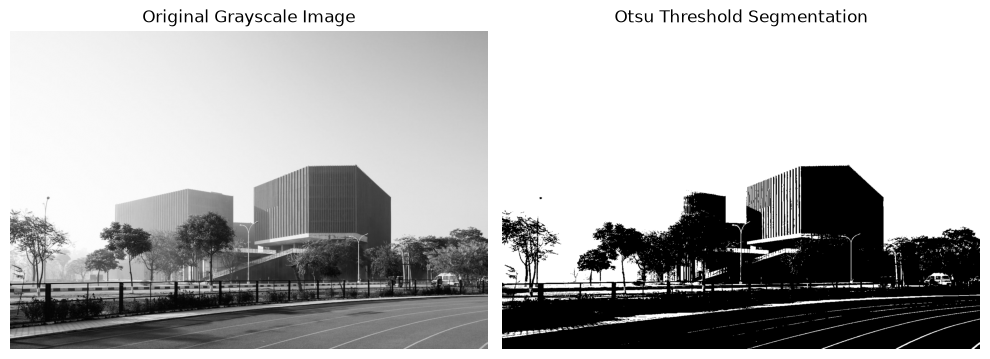

In [2]:

import cv2
import matplotlib.pyplot as plt

# Read grayscale image
img = cv2.imread('image.jpg', 0)

if img is None:
    raise ValueError("Image not found!")

# Apply Otsu's thresholding
threshold, otsu_img = cv2.threshold(
    img,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Display threshold value
print("Optimal Threshold Value:", threshold)

# Display original and segmented images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Grayscale Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(otsu_img, cmap='gray')
plt.title('Otsu Threshold Segmentation')
plt.axis('off')

plt.tight_layout()
plt.show()
